Stage 02: Dataset Access:
Project: Spam Email Detection Using Naïve Bayes  
Yousuf Al Jabri – A310 Fall 2026

I am keeping my approved Stage 01 project: Spam Email Detection Using Naïve Bayes*, based on Python Machine Learning Workbook for Beginners* (AI Publishing, 2020), Project 2.

Dataset: emails.csv (Kaggle spam filter dataset), saved in this folder. It has two columns:
text: the full email, starting with its subject line
spam: the label, 1 = spam and 0 = not spam ("ham")

This notebook shows that I can read, load and manipulate the dataset.

1. Read and load the dataset

In [2]:
import pandas as pd
try:
    emails = pd.read_csv('emails.csv')
except FileNotFoundError:
    url = 'https://raw.githubusercontent.com/c212/a310-fall2026-yaljabri/main/Project/Stage02/emails.csv'
    emails = pd.read_csv(url)

print("Rows and columns:", emails.shape)
emails.head()

Rows and columns: (5728, 2)


,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


2. Look at the structure

In [3]:
emails.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB


In [4]:
print("Missing values per column:")
print(emails.isnull().sum())
print("\nDuplicate emails:", emails.duplicated().sum())

Missing values per column:
text    0
spam    0
dtype: int64

Duplicate emails: 33


3. Spam vs. not spam

In [5]:
counts = emails['spam'].value_counts()
print(counts)
print("\nPercent spam: {:.1f}%".format(emails['spam'].mean() * 100))

spam
0    4360
1    1368
Name: count, dtype: int64

Percent spam: 23.9%


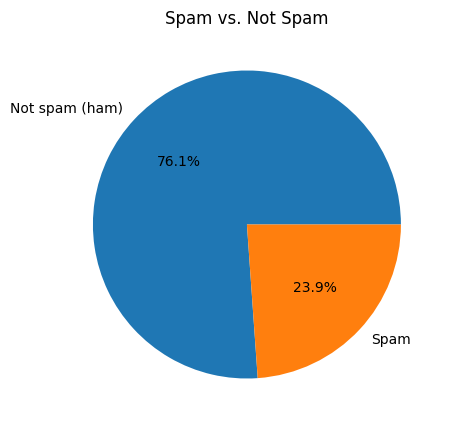

In [6]:
import matplotlib.pyplot as plt

counts.rename({0: 'Not spam (ham)', 1: 'Spam'}).plot(kind='pie', autopct='%1.1f%%', figsize=(5, 5))
plt.title('Spam vs. Not Spam')
plt.ylabel('')
plt.show()

4. Simple manipulation

In [7]:
# Remove duplicate emails
emails = emails.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", emails.shape)

# Add a column with the number of words in each email
emails['word_count'] = emails['text'].str.split().str.len()

# Average email length for spam vs. not spam
print("\nAverage number of words:")
print(emails.groupby('spam')['word_count'].mean().round(1))

After removing duplicates: (5695, 2)

Average number of words:
spam
0    346.3
1    266.4
Name: word_count, dtype: float64


In [8]:
# Remove the "Subject:" prefix and make the text lowercase (a first cleaning step)
emails['clean_text'] = emails['text'].str.replace('Subject:', '', regex=False).str.strip().str.lower()

# Show one spam email and one non-spam email
print("SPAM example:\n", emails.loc[emails['spam'] == 1, 'clean_text'].iloc[0][:300], "\n")
print("NOT SPAM example:\n", emails.loc[emails['spam'] == 0, 'clean_text'].iloc[0][:300])

SPAM example:
 naturally irresistible your corporate identity  lt is really hard to recollect a company : the  market is full of suqgestions and the information isoverwhelminq ; but a good  catchy logo , stylish statlonery and outstanding website  will make the task much easier .  we do not promise that havinq ord 

NOT SPAM example:
 hello guys ,  i ' m " bugging you " for your completed questionnaire and for a one - page  bio / statement on your thoughts on " business edu and the new economy " . if  my records are incorrect please re - ship your responses to me . i want to  put everything together next week so that i can ship i


In [9]:
emails[['clean_text', 'spam', 'word_count']].head()

,clean_text,spam,word_count
0,naturally irresistible your corporate identity...,1,324
1,the stock trading gunslinger fanny is merrill...,1,89
2,unbelievable new homes made easy im wanting t...,1,87
3,4 color printing special request additional i...,1,98
4,"do not have money , get software cds from here...",1,52


Summary:
The dataset loads correctly: 5,728 emails, 2 columns, no missing values, and about 24% spam. I removed 33 duplicate emails, added a word-count column, compared email length for spam vs. not spam, and did a first cleaning step on the text. In the next stage I will remove stop words, convert the text to numbers with TF-IDF, and train the Naïve Bayes model.